In [1]:
import time
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

In [2]:
torch.manual_seed(42)
np.random.seed(42)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Wykorzystywane urządzenie:', DEVICE)

Wykorzystywane urządzenie: cpu


In [6]:
def gen_delayed_adding(N, L, delay=8):
    """
    Generuje dane dla adding problem z opóźnionym wskaźnikiem.
    N - liczba sekwencji
    L - długość sekwencji
    delay - opóźnienie wskaźnika względem wartości (domyślnie 8)
    """
    val = np.random.rand(N, L, 1).astype(np.float32)
    mark = np.zeros((N, L, 1), np.float32)
    y = np.zeros((N, 1), np.float32)

    for i in range(N):
        p = np.random.choice(range(delay, L), 2, replace=False)
        mark[i, p, 0] = 1.0
        y[i, 0] = val[i, p - delay, 0].sum()

    x = np.concatenate([val, mark], axis=2)
    return torch.tensor(x).to(DEVICE), torch.tensor(y).to(DEVICE)

In [7]:
print("\n Test ręczny generatora ")
xx_test, yy_test = gen_delayed_adding(1, 20, delay=8)
poz_znacznikow = np.where(xx_test[0, :, 1].cpu().numpy() == 1)[0]
poz_wartosci = poz_znacznikow - 8
print('Pozycje znaczników (1-based):', poz_znacznikow + 1)
print('Pozycje wskazywanych wartości (1-based):', poz_wartosci + 1)
print('Wartości w tych miejscach:', xx_test[0, poz_wartosci, 0].cpu().numpy().round(3))
print('Obliczona suma (cel):', float(yy_test[0, 0]))


 Test ręczny generatora 
Pozycje znaczników (1-based): [10 17]
Pozycje wskazywanych wartości (1-based): [2 9]
Wartości w tych miejscach: [0.951 0.601]
Obliczona suma (cel): 1.5518293380737305


In [15]:
class RNNNet(nn.Module):
    def __init__(self, typ, hidden=64):
        super().__init__()
        self.rnn = {'RNN': nn.RNN, 'LSTM': nn.LSTM, 'GRU': nn.GRU}[typ](2, hidden, batch_first=True)
        self.fc = nn.Linear(hidden, 1)

    def forward(self, x):
        out, _ = self.rnn(x)
        return self.fc(out[:, -1, :])

class Conv1DNet(nn.Module):
    def __init__(self, ch=64, dilations=[1, 2, 4]):
        super().__init__()
        layers = []
        in_channels = 2
        for d in dilations:
            layers.append(nn.Conv1d(in_channels, ch, kernel_size=3, padding=d, dilation=d))
            layers.append(nn.ReLU())
            in_channels = ch
        self.net = nn.Sequential(*layers)
        self.fc = nn.Linear(ch, 1)

    def forward(self, x):
        h = self.net(x.transpose(1, 2)).mean(dim=2)
        return self.fc(h)

def licz_parametry(m):
    return sum(p.numel() for p in m.parameters())

In [16]:
def trenuj(model, Xtr, Ytr, Xte, Yte, epoki=30, lr=5e-3, batch=128):
    model = model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    Lf = nn.MSELoss()
    N = Xtr.shape[0]

    t0 = time.time()
    for ep in range(epoki):
        model.train()
        perm = torch.randperm(N)
        for i in range(0, N, batch):
            idx = perm[i:i+batch]
            opt.zero_grad()
            loss = Lf(model(Xtr[idx]), Ytr[idx])
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()

    czas = time.time() - t0
    model.eval()
    with torch.no_grad():
        mse = Lf(model(Xte), Yte).item()
    return mse, czas

In [17]:
N_train = 4000
N_test = 800
epoki = 30
batch_size = 128

dlugosci = [50, 100]
wszystkie_wyniki = {}

for L in dlugosci:
    print(f"\n Uruchomienie dla L = {L} ")
    Xtr, Ytr = gen_delayed_adding(N_train, L)
    Xte, Yte = gen_delayed_adding(N_test, L)

    baseline_mse = ((Yte - Ytr.mean()) ** 2).mean().item()
    print(f"Baseline (stała predykcja) Test MSE = {baseline_mse:.4f}")

    modele = {
        'SimpleRNN': RNNNet('RNN', hidden=64),
        'LSTM': RNNNet('LSTM', hidden=64),
        'GRU': RNNNet('GRU', hidden=64),
        'Conv1D': Conv1DNet(ch=64, dilations=[1, 2, 4])
    }

    wyniki_L = {'Baseline': {'mse': baseline_mse, 'czas': 0.0, 'params': 0}}

    for nazwa, m in modele.items():
        mse, czas = trenuj(m, Xtr, Ytr, Xte, Yte, epoki=epoki, lr=5e-3, batch=batch_size)
        n_params = licz_parametry(m)
        wyniki_L[nazwa] = {'mse': mse, 'czas': czas, 'params': n_params}
        print(f"{nazwa:10s}  MSE={mse:.5f}  czas={czas:4.1f}s  params={n_params}")

    wszystkie_wyniki[L] = wyniki_L


 Uruchomienie dla L = 50 
Baseline (stała predykcja) Test MSE = 0.1703
SimpleRNN   MSE=0.17376  czas=13.9s  params=4417
LSTM        MSE=0.17166  czas=40.5s  params=17473
GRU         MSE=0.08381  czas=38.8s  params=13121
Conv1D      MSE=0.15927  czas=38.0s  params=25217

 Uruchomienie dla L = 100 
Baseline (stała predykcja) Test MSE = 0.1779
SimpleRNN   MSE=0.17873  czas=26.1s  params=4417
LSTM        MSE=0.17816  czas=92.9s  params=17473
GRU         MSE=0.17499  czas=77.8s  params=13121
Conv1D      MSE=0.17916  czas=69.6s  params=25217


In [18]:
print("\n Dodatkowe warianty dla L = 100 ")
Xtr_100, Ytr_100 = gen_delayed_adding(N_train, 100)
Xte_100, Yte_100 = gen_delayed_adding(N_test, 100)

m_rnn_32 = RNNNet('RNN', hidden=32)
mse_r32, czas_r32 = trenuj(m_rnn_32, Xtr_100, Ytr_100, Xte_100, Yte_100, epoki=epoki)
print(f"SimpleRNN (hidden=32) -> MSE={mse_r32:.5f}, czas={czas_r32:.1f}s, params={licz_parametry(m_rnn_32)}")

m_conv_111 = Conv1DNet(ch=64, dilations=[1, 1, 1])
mse_c111, czas_c111 = trenuj(m_conv_111, Xtr_100, Ytr_100, Xte_100, Yte_100, epoki=epoki)
print(f"Conv1D ([1,1,1])       -> MSE={mse_c111:.5f}, czas={czas_c111:.1f}s, params={licz_parametry(m_conv_111)}")


 Dodatkowe warianty dla L = 100 
SimpleRNN (hidden=32) -> MSE=0.18050, czas=16.9s, params=1185
Conv1D ([1,1,1])       -> MSE=0.17612, czas=62.7s, params=25217


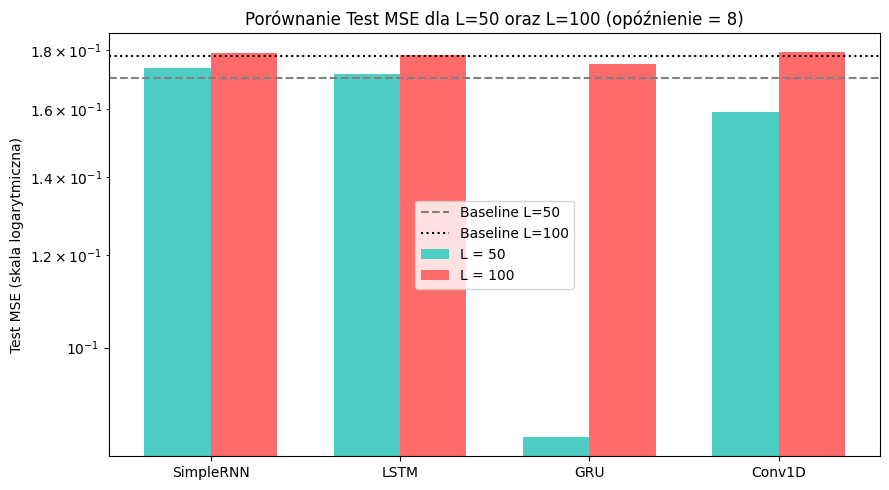

In [19]:
architektury = ['SimpleRNN', 'LSTM', 'GRU', 'Conv1D']
mse_50 = [wszystkie_wyniki[50][a]['mse'] for a in architektury]
mse_100 = [wszystkie_wyniki[100][a]['mse'] for a in architektury]

x = np.arange(len(architektury))
width = 0.35

plt.figure(figsize=(9, 5))
plt.bar(x - width/2, mse_50, width, label='L = 50', color='#4ecdc4')
plt.bar(x + width/2, mse_100, width, label='L = 100', color='#ff6b6b')
plt.axhline(wszystkie_wyniki[50]['Baseline']['mse'], color='gray', linestyle='--', label='Baseline L=50')
plt.axhline(wszystkie_wyniki[100]['Baseline']['mse'], color='black', linestyle=':', label='Baseline L=100')

plt.ylabel('Test MSE (skala logarytmiczna)')
plt.yscale('log')
plt.title('Porównanie Test MSE dla L=50 oraz L=100 (opóźnienie = 8)')
plt.xticks(x, architektury)
plt.legend()
plt.tight_layout()
plt.show()